# Skills Pattern (스킬 기반 패턴 - Progressive Disclosure)

**Progressive Disclosure**는 에이전트가 필요한 정보를 **필요할 때만** 로드하는 방식입니다.
시스템 프롬프트에는 스킬의 **간단한 설명**만 노출하고, 상세 스키마·비즈니스 로직은 `load_skill` 도구로 불러옵니다.

## 주요 포인트 정리

1. **Progressive Disclosure**: 스킬 설명만 먼저 노출, 상세 내용은 load_skill로 필요 시 로드
2. **SkillMiddleware**: 시스템 프롬프트에 스킬 설명 추가, load_skill 도구 등록
3. **컨텍스트 절약**: 필요한 1~2개 스킬만 로드해 토큰 사용 최소화
4. **팀 확장성**: 도메인별 스킬을 독립적으로 추가·유지보수 가능
5. **트레이드오프**:
   - 스킬을 필요할 때 로드하므로 첫 요청에 도구 호출이 추가되어 **지연(latency)** 이 늘어남
   - 기본 구현은 프롬프트로 load_skill 사용을 **유도할 뿐 강제하지 못함** → 아래 실습문제에서 상태 기반 제약으로 보완

**참고**: [LangChain 공식 문서 - Build a SQL assistant with on-demand skills](https://docs.langchain.com/oss/python/langchain/multi-agent/skills-sql-assistant)

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [2]:
from typing import TypedDict
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain.agents import create_agent
from langchain.agents.middleware import AgentMiddleware, ModelRequest, ModelResponse
from langgraph.checkpoint.memory import InMemorySaver
from typing import Callable

model = init_chat_model(
    os.environ["OPENAI_MODEL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)

## 1. 스킬 정의 (Skill TypedDict)

각 스킬은 name, description(시스템 프롬프트에 노출), content(도구 호출 시 로드)를 가집니다.

In [8]:
# Skill 데이터 구조 정의
class Skill(TypedDict):
    """
    에이전트가 필요할 때(on-demand) 로딩할 수 있는 스킬 정의 구조.

    Skills Pattern에서는 모든 지식을 한 번에 프롬프트에 넣지 않고,
    아래 3가지 요소로 분리하여 관리한다.

    name: 
        - 스킬 고유 식별자, load_skill 도구 호출 시 사용됨

    description:
        - 에이전트가 어떤 스킬이 존재하는지 판단하는 용도
        - SkillMiddleware에서 system prompt에 삽입됨

    content:
        - 실제 상세 지식 (스키마, 규칙, 예시 쿼리 등)
        - 필요할 때만 Tool 호출을 통해 컨텍스트에 로딩됨
    """
    name: str
    description: str
    content: str


# 에이전트가 사용할 수 있는 모든 스킬 목록
SKILLS: list[Skill] = [
    # ------------------------------------------------------------
    # 매출 분석 스킬
    # ------------------------------------------------------------
    {
        "name": "sales_analytics",
        "description": "매출 데이터 분석용 DB 스키마 및 비즈니스 로직 (고객, 주문, 매출).",
        "content": """# Sales Analytics 스키마

## 테이블
- customers: customer_id, name, email, signup_date, status, customer_tier
- orders: order_id, customer_id, order_date, status, total_amount, sales_region
- order_items: item_id, order_id, product_id, quantity, unit_price, discount_percent

## 비즈니스 로직
- 활성 고객: status = 'active' 이고 signup_date가 90일 이상 경과
- 매출: status = 'completed'인 주문만, total_amount 사용
- 고가 주문: total_amount > 1000

## 예시 쿼리
-- 최근 분기 매출 상위 10명 고객
SELECT c.customer_id, c.name, c.customer_tier, SUM(o.total_amount) as total_revenue
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
WHERE o.status = 'completed' AND o.order_date >= CURRENT_DATE - INTERVAL '3 months'
GROUP BY c.customer_id, c.name, c.customer_tier
ORDER BY total_revenue DESC LIMIT 10;
""",
    },

    # ------------------------------------------------------------
    # 재고 관리 스킬
    # ------------------------------------------------------------
    {
        "name": "inventory_management",
        "description": "재고 추적용 DB 스키마 및 비즈니스 로직 (제품, 창고, 재고 수준).",
        "content": """# Inventory Management 스키마

## 테이블
- products: product_id, product_name, sku, category, unit_cost, reorder_point, discontinued
- warehouses: warehouse_id, warehouse_name, location, capacity
- inventory: inventory_id, product_id, warehouse_id, quantity_on_hand, last_updated
- stock_movements: movement_id, product_id, warehouse_id, movement_type, quantity, movement_date

## 비즈니스 로직
- 재주문 필요: 모든 창고의 quantity_on_hand 합이 제품의 reorder_point 이하
- 활성 제품만: discontinued = false (별도 분석 시 제외)
- 재고 평가: quantity_on_hand * unit_cost
""",
    },
]

## 2. load_skill 도구

스킬 이름으로 전체 content를 로드해 에이전트 컨텍스트에 넣습니다.

In [9]:
@tool
def load_skill(skill_name: str) -> str:
    """
    특정 스킬의 전체 내용을 에이전트 컨텍스트에 로드하는 Tool 함수

    역할:
        - Skills Pattern에서 "Progressive Disclosure"를 구현하는 핵심 도구
        - 에이전트가 필요한 스킬을 선택하면 해당 스킬의 상세 내용을 불러와 모델 컨텍스트에 삽입하는 역할 수행

    동작 방식:
        1️⃣ 에이전트가 skill_name을 기반으로 필요한 스킬을 선택
        2️⃣ SKILLS 목록에서 해당 스킬 검색
        3️⃣ 스킬의 content(스키마, 비즈니스 규칙, 예시 등)를 반환
        4️⃣ 반환된 내용은 ToolMessage 형태로 대화 컨텍스트에 추가됨

    Args:
        skill_name: 로드할 스킬 이름
           
    Returns:
        str: 스킬 상세 내용 또는 오류 메시지
    """

    # ------------------------------------------------------------
    # SKILLS 레지스트리에서 요청된 스킬 검색
    # ------------------------------------------------------------
    for skill in SKILLS:
        # 스킬 이름이 일치하면 해당 스킬 반환
        if skill["name"] == skill_name:
            # 반환된 문자열은 ToolMessage로 변환되어 모델 컨텍스트에 삽입됨
            return f"Loaded skill: {skill_name}\n\n{skill['content']}"

    # 사용자 또는 에이전트가 잘못된 스킬 이름을 요청했을 때 사용 가능한 스킬 목록을 안내
    available = ", ".join(s["name"] for s in SKILLS)

    return f"스킬 '{skill_name}'을 찾을 수 없습니다. 사용 가능: {available}"

## 3. SkillMiddleware

시스템 프롬프트에 **스킬 설명만** 추가하고, load_skill 도구를 등록합니다.

In [10]:
class SkillMiddleware(AgentMiddleware):
    """
    시스템 프롬프트에 "사용 가능한 스킬 목록"을 주입하는 Middleware

    역할:
        - 에이전트가 어떤 스킬이 존재하는지 알 수 있도록 메타 정보 제공
        - Progressive Disclosure 구조에서 "Skill Discovery" 단계 담당
        - 모델이 필요 시 load_skill Tool을 호출하도록 유도

    특징:
        ✔ 모델 호출 직전에 실행 (wrap_model_call 단계)
        ✔ 전체 스킬 내용을 넣지 않고 "설명(description)"만 노출
        ✔ 실제 스킬 내용은 load_skill Tool을 통해 on-demand 로딩
    """

    # Middleware에서 사용할 Tool 등록
    tools = [load_skill]

    def __init__(self):
        """
        스킬 목록을 시스템 프롬프트에 삽입할 문자열 형태로 변환

        SKILLS 레지스트리에 있는 모든 스킬의 이름, 설명을 리스트로 구성
        """

        # 각 스킬을 Markdown 리스트 형태로 구성
        skills_list = [
            f"- **{s['name']}**: {s['description']}"
            for s in SKILLS
        ]

        # 문자열로 합쳐 저장
        self.skills_prompt = "\n".join(skills_list)

    def wrap_model_call(
        self,
        request: ModelRequest,
        handler: Callable[[ModelRequest], ModelResponse],
    ) -> ModelResponse:
        """
        모델 호출 직전에 실행되는 Middleware Hook

        역할:
            ✔ 시스템 프롬프트에 스킬 목록 추가
            ✔ 모델이 어떤 스킬을 사용할 수 있는지 안내
            ✔ load_skill Tool 사용을 유도

        실행 시점:
            before_model 단계 (LLM 호출 직전)
        """

        # 스킬 안내 텍스트 구성
        skills_addendum = (
            f"\n\n## 사용 가능한 스킬\n\n{self.skills_prompt}\n\n"
            "필요한 유형의 요청을 처리할 때 load_skill 도구로 해당 스킬의 상세 내용을 로드하세요."
        )

        # 현재 시스템 프롬프트 가져오기
        current = getattr(request, "system_prompt", None)

        # system_prompt가 없으면 system_message에서 추출
        if current is None and hasattr(request, "system_message") and request.system_message:
            current = getattr(request.system_message, "content", "") or ""

        # 둘 다 없으면 빈 문자열 사용
        if current is None:
            current = ""

        # 기존 시스템 프롬프트 + 스킬 목록 결합
        new_prompt = current + skills_addendum

        # 수정된 시스템 프롬프트로 모델 호출 진행
        # override()는 ModelRequest를 복사하면서 일부 필드만 수정
        return handler(request.override(system_prompt=new_prompt))

## 4. 에이전트 생성

SkillMiddleware와 checkpointer로 대화 상태를 유지합니다.

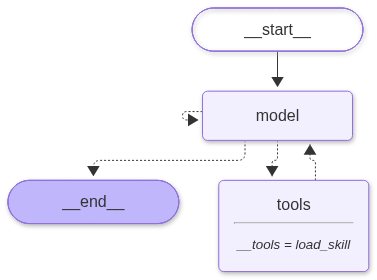

In [11]:
agent = create_agent(
    model,
    system_prompt="당신은 비즈니스 DB용 SQL 쿼리 작성 도우미입니다. 사용자 질문에 맞는 SQL을 작성하세요.",
    middleware=[SkillMiddleware()],
    checkpointer=InMemorySaver(),
)

agent

## 5. Progressive Disclosure 테스트

질문 시 에이전트가 load_skill(sales_analytics)을 호출한 뒤 스키마를 활용해 쿼리를 작성합니다.

In [13]:
import uuid
from langchain_core.messages import HumanMessage

# 대화 스레드 ID 생성
thread_id = str(uuid.uuid4())

config = {
    "configurable": {
        "thread_id": thread_id
    }
}

result = agent.invoke(
    {
        "messages": [
            HumanMessage(
                content="지난달 매출 1000달러 이상인 주문을 한 고객 목록을 조회하는 SQL을 작성해줘."
            )
        ]
    },
    config,  
)

for msg in result["messages"]:
    for call in getattr(msg, "tool_calls", None) or []:
        print(f"[{msg.type}] 도구 호출 → {call['name']}({call['args']})")

    if msg.text:
        # 도구 결과(ToolMessage)는 첫 줄만, 나머지 메시지는 전체 출력
        body = msg.text.splitlines()[0] + " ..." if msg.type == "tool" else msg.text
        print(f"[{msg.type}] {body}\n")

[human] 지난달 매출 1000달러 이상인 주문을 한 고객 목록을 조회하는 SQL을 작성해줘.

[ai] 도구 호출 → load_skill({'skill_name': 'sales_analytics'})
[tool] Loaded skill: sales_analytics ...

[ai] ```sql
SELECT DISTINCT
    c.customer_id,
    c.name,
    c.email
FROM customers c
JOIN orders o
    ON o.customer_id = c.customer_id
WHERE o.status = 'completed'
  AND o.total_amount >= 1000
  AND o.order_date >= DATE_TRUNC('month', CURRENT_DATE) - INTERVAL '1 month'
  AND o.order_date < DATE_TRUNC('month', CURRENT_DATE)
ORDER BY c.name;
```

